# 08_ROCOv2_Conformal_Prediction

**Purpose:** Establish a proper, independent calibration set (resolving the
warning repeated in Notebooks 05/06/07) and apply per-label split conformal
prediction to all three trained models — DenseNet121 (05), BiomedCLIP
zero-shot (06), and the Proposed VLM (07) — so their trustworthiness
(coverage guarantee + prediction-set efficiency), not just point accuracy,
can be compared.

### Methodology (confirmed, not assumed)
- **Calibration source:** the current Test set (`test_prepared.csv`) is
  split 50/50, fixed seed, into a new `calibration_prepared.csv` and
  `test_final_prepared.csv` — because Test is the only portion of the data
  provably untouched by every modeling decision in 05–07 (confirmed
  explicitly in each of their final reports). Validation is **not** reused
  as calibration data, since it was already used for early stopping,
  checkpoint selection, and (in 06) threshold optimization.
- **Conformal method:** per-label independent split conformal prediction
  (LAC — Least Ambiguous Set-valued Classifier, Sadinle et al. 2019),
  applied to each of the 18 labels as its own binary conformal problem.
  Nonconformity score for label *c*: `1 - p_c` if the true label is
  positive, `p_c` if negative. A per-label threshold `q̂_c` is calibrated
  from the Calibration set with the standard finite-sample correction,
  then applied to Test-final to build a **prediction set** per label per
  sample (one of `{}`, `{0}`, `{1}`, `{0,1}`).
- **Target coverage:** 90% (α = 0.10), i.e. each label's prediction set is
  guaranteed to contain the true label with marginal probability ≥ 0.90
  under exchangeability.
- **Scope:** all three models — enables a direct "does the proposed VLM
  produce not just more accurate but more efficient (tighter) trustworthy
  prediction sets?" comparison.
- **No re-training, no re-loading of any model.** Each of 05/06/07 already
  saved a `*_predictions.csv` with per-sample probabilities for every
  Validation/Test ID — this notebook only reads and filters those, split
  by ID membership into Calibration vs. Test-final. Notebooks 01–07 are
  not modified or re-run.
- **Point-prediction metrics are also recomputed on Test-final** for each
  model (same full metric suite as 05/06/07), so every number from this
  notebook onward uses the same, smaller Test set consistently — 05/06/07's
  original full-Test numbers remain the historical record, not superseded.

### Inputs
- `Prepared/test_prepared.csv`, `train_prepared.csv`,
  `validation_prepared.csv`, `label_mapping.json` (Notebook 02).
- `Prepared/Baselines/DenseNet121_Unimodal/densenet121_predictions.csv` (05)
- `Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_predictions.csv` (06)
- `Prepared/Baselines/BiomedCLIP_VLM_Trained/vlm_predictions.csv` (07)

### Outputs
- New authoritative splits: `Prepared/calibration_prepared.csv`,
  `Prepared/test_final_prepared.csv` (protected against silent overwrite,
  same convention as every other authoritative artifact in this project).
- Under `Prepared/ConformalPrediction/`: per-model re-evaluated Test-final
  metrics, per-label conformal thresholds/coverage/set-size results,
  comparison figures (vector PDF + 300 DPI PNG), `reproducibility.json`,
  `artifact_manifest.json`.

### Non-goals
No counterfactual explanations, no trust score estimation, no XAI. Those
belong to later notebooks.

In [2]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import time
import random
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

CONFORMAL_DIR = PREPARED_DIR / "ConformalPrediction"
FIG_DIR = CONFORMAL_DIR / "figures"
for d in [CONFORMAL_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
VALID_PREPARED_PATH = PREPARED_DIR / "validation_prepared.csv"
TEST_PREPARED_PATH = PREPARED_DIR / "test_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

# New authoritative artifacts produced by THIS notebook
CALIBRATION_PREPARED_PATH = PREPARED_DIR / "calibration_prepared.csv"
TEST_FINAL_PREPARED_PATH = PREPARED_DIR / "test_final_prepared.csv"

# Existing model artifacts (read-only — no model is reloaded or re-run)
MODEL_REGISTRY = [
    {
        "name": "densenet121",
        "display_name": "DenseNet121 (image-only baseline)",
        "predictions_path": PREPARED_DIR / "Baselines" / "DenseNet121_Unimodal" / "densenet121_predictions.csv",
        "prob_suffix": "_prob",
    },
    {
        "name": "biomedclip_zeroshot",
        "display_name": "BiomedCLIP (zero-shot VLM baseline)",
        "predictions_path": PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_ZeroShot" / "biomedclip_predictions.csv",
        "prob_suffix": "_score",
    },
    {
        "name": "proposed_vlm",
        "display_name": "Proposed VLM (fine-tuned BiomedCLIP)",
        "predictions_path": PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained" / "vlm_predictions.csv",
        "prob_suffix": "_prob",
    },
]

# Outputs
CONFORMAL_CONFIG_PATH = CONFORMAL_DIR / "conformal_config.json"
TEST_FINAL_METRICS_PATH = CONFORMAL_DIR / "test_final_point_metrics_all_models.csv"
CONFORMAL_PER_LABEL_PATH = CONFORMAL_DIR / "conformal_per_label_results.csv"
CONFORMAL_SUMMARY_PATH = CONFORMAL_DIR / "conformal_summary_all_models.csv"
COVERAGE_FIGURE_PDF = FIG_DIR / "coverage_comparison.pdf"
COVERAGE_FIGURE_PNG = FIG_DIR / "coverage_comparison_300dpi.png"
SETSIZE_FIGURE_PDF = FIG_DIR / "prediction_set_size_comparison.pdf"
SETSIZE_FIGURE_PNG = FIG_DIR / "prediction_set_size_comparison_300dpi.png"
REPRODUCIBILITY_PATH = CONFORMAL_DIR / "reproducibility.json"
MANIFEST_PATH = CONFORMAL_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ALPHA = 0.10
TARGET_COVERAGE = 1 - ALPHA

print("=" * 80)
print("NOTEBOOK 08 — CONFORMAL PREDICTION")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("CONFORMAL_DIR:", CONFORMAL_DIR)
print("Random seed:", SEED)
print(f"Target coverage: {TARGET_COVERAGE:.0%} (alpha={ALPHA})")


Mounted at /content/drive
Google Drive available.
NOTEBOOK 08 — CONFORMAL PREDICTION
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
CONFORMAL_DIR: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction
Random seed: 42
Target coverage: 90% (alpha=0.1)


## 1. Verify required inputs

Requires Notebook 02's splits and all three models' saved prediction files
from 05/06/07 — nothing is re-run if any of these are missing, this
notebook simply refuses to guess.

In [3]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "validation_prepared.csv": VALID_PREPARED_PATH,
    "test_prepared.csv": TEST_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
}
for model_info in MODEL_REGISTRY:
    required_inputs[f"{model_info['name']}_predictions.csv"] = model_info["predictions_path"]

missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 08 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02, 05, 06, and 07 first."
    )

print("PASS — Required Notebook 02/05/06/07 artifacts all exist.")
for name, path in required_inputs.items():
    print(f"{name:40s}: {path}")


PASS — Required Notebook 02/05/06/07 artifacts all exist.
train_prepared.csv                      : /content/drive/MyDrive/ROCOv2/Prepared/train_prepared.csv
validation_prepared.csv                 : /content/drive/MyDrive/ROCOv2/Prepared/validation_prepared.csv
test_prepared.csv                       : /content/drive/MyDrive/ROCOv2/Prepared/test_prepared.csv
label_mapping.json                      : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json
densenet121_predictions.csv             : /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal/densenet121_predictions.csv
biomedclip_zeroshot_predictions.csv     : /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_predictions.csv
proposed_vlm_predictions.csv            : /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained/vlm_predictions.csv


## 2. Derive the Calibration / Test-final split (50/50, fixed seed)

The current Test set is the only data provably untouched by any modeling
decision in 05/06/07. Splitting it in half keeps both halves equally
untouched: Calibration for conformal threshold fitting, Test-final for the
one remaining final evaluation. This does **not** modify `test_prepared.csv`
— it derives two new files, refusing to overwrite them if they already
exist from a previous run.

In [4]:
# ============================================================
# CELL 3 — DERIVE CALIBRATION / TEST-FINAL SPLIT
# ============================================================

test_df_full = pd.read_csv(TEST_PREPARED_PATH)
n_test_full = len(test_df_full)

if CALIBRATION_PREPARED_PATH.exists() and TEST_FINAL_PREPARED_PATH.exists() and not ALLOW_OVERWRITE:
    print("REUSING existing calibration/test_final split — not regenerating.")
    calibration_df = pd.read_csv(CALIBRATION_PREPARED_PATH)
    test_final_df = pd.read_csv(TEST_FINAL_PREPARED_PATH)
else:
    rng = np.random.RandomState(SEED)
    shuffled_idx = rng.permutation(n_test_full)
    split_point = n_test_full // 2

    calibration_idx = shuffled_idx[:split_point]
    test_final_idx = shuffled_idx[split_point:]

    calibration_df = test_df_full.iloc[calibration_idx].reset_index(drop=True)
    test_final_df = test_df_full.iloc[test_final_idx].reset_index(drop=True)

    safe_save_csv(CALIBRATION_PREPARED_PATH, calibration_df)
    safe_save_csv(TEST_FINAL_PREPARED_PATH, test_final_df)

print("=" * 80)
print("CALIBRATION / TEST-FINAL SPLIT")
print("=" * 80)
print(f"Original Test:  {n_test_full:,}")
print(f"Calibration:    {len(calibration_df):,}")
print(f"Test-final:     {len(test_final_df):,}")

# ------------------------------------------------------------
# Leakage checks — must never fail
# ------------------------------------------------------------
train_ids = set(pd.read_csv(TRAIN_PREPARED_PATH)["ID"].astype(str))
val_ids = set(pd.read_csv(VALID_PREPARED_PATH)["ID"].astype(str))
calibration_ids = set(calibration_df["ID"].astype(str))
test_final_ids = set(test_final_df["ID"].astype(str))

assert not (calibration_ids & test_final_ids), "Calibration/Test-final ID overlap detected."
assert not (train_ids & calibration_ids), "Train/Calibration ID overlap detected."
assert not (train_ids & test_final_ids), "Train/Test-final ID overlap detected."
assert not (val_ids & calibration_ids), "Validation/Calibration ID overlap detected."
assert not (val_ids & test_final_ids), "Validation/Test-final ID overlap detected."
assert calibration_ids | test_final_ids == set(test_df_full["ID"].astype(str)), \
    "Calibration + Test-final does not reconstruct the original Test set exactly."

print("\nPASS — No leakage between Calibration/Test-final and Train/Validation, "
      "and the split exactly partitions the original Test set.")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/calibration_prepared.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/test_final_prepared.csv
CALIBRATION / TEST-FINAL SPLIT
Original Test:  9,870
Calibration:    4,935
Test-final:     4,935

PASS — No leakage between Calibration/Test-final and Train/Validation, and the split exactly partitions the original Test set.


## 3. Load the label taxonomy

In [5]:
# ============================================================
# CELL 4 — LOAD LABEL MAPPING
# ============================================================

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."
LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

print(f"Label taxonomy ({N_LABELS} labels):")
for i, (col, name) in enumerate(zip(LABEL_COLUMNS, LABEL_NAMES)):
    print(f"  {i:02d} | {col} | {name}")


Label taxonomy (18 labels):
  00 | label_C0000726 | Abdomen
  01 | label_C0002978 | Angiogram
  02 | label_C0006141 | Breast
  03 | label_C0023216 | Lower Extremity
  04 | label_C0024485 | Magnetic Resonance Imaging
  05 | label_C0030797 | Pelvis
  06 | label_C0032743 | Positron-Emission Tomography
  07 | label_C0037303 | Bone structure of cranium
  08 | label_C0037949 | Vertebral column
  09 | label_C0040405 | X-Ray Computed Tomography
  10 | label_C0041618 | Ultrasonography
  11 | label_C0205106 | Transverse
  12 | label_C0205129 | Sagittal
  13 | label_C0817096 | Chest
  14 | label_C1140618 | Upper Extremity
  15 | label_C1306645 | Plain x-ray
  16 | label_C1996865 | Postero-Anterior
  17 | label_C1999039 | Anterior-Posterior


## 4. Load each model's existing predictions and split by ID membership

No model is reloaded and no inference is re-run. Each model's saved
predictions are filtered to `Split == "test"`, then split into Calibration
and Test-final subsets purely by ID membership in the split derived above.
Row-count assertions guard against a predictions file silently missing any
ID (which would otherwise fail silently downstream).

In [6]:
# ============================================================
# CELL 5 — LOAD AND SPLIT EACH MODEL'S PREDICTIONS
# ============================================================

model_scores = {}

for model_info in MODEL_REGISTRY:
    name = model_info["name"]
    preds_df = pd.read_csv(model_info["predictions_path"])
    preds_df["ID"] = preds_df["ID"].astype(str)

    test_preds = preds_df.loc[preds_df["Split"] == "test"].copy()

    calib_scores = test_preds.loc[test_preds["ID"].isin(calibration_ids)].set_index("ID")
    test_final_scores = test_preds.loc[test_preds["ID"].isin(test_final_ids)].set_index("ID")

    calib_scores = calib_scores.loc[[i for i in calibration_df["ID"].astype(str) if i in calib_scores.index]]
    test_final_scores = test_final_scores.loc[
        [i for i in test_final_df["ID"].astype(str) if i in test_final_scores.index]
    ]

    assert len(calib_scores) == len(calibration_df), (
        f"{name}: predictions file covers {len(calib_scores)}/{len(calibration_df)} "
        "Calibration IDs — incomplete predictions file."
    )
    assert len(test_final_scores) == len(test_final_df), (
        f"{name}: predictions file covers {len(test_final_scores)}/{len(test_final_df)} "
        "Test-final IDs — incomplete predictions file."
    )

    model_scores[name] = {"calibration": calib_scores, "test_final": test_final_scores}
    print(f"{model_info['display_name']:45s}: "
          f"{len(calib_scores):,} calibration rows, {len(test_final_scores):,} test-final rows.")

print("\nPASS — Every model's predictions file fully covers both Calibration and Test-final.")


DenseNet121 (image-only baseline)            : 4,935 calibration rows, 4,935 test-final rows.
BiomedCLIP (zero-shot VLM baseline)          : 4,935 calibration rows, 4,935 test-final rows.
Proposed VLM (fine-tuned BiomedCLIP)         : 4,935 calibration rows, 4,935 test-final rows.

PASS — Every model's predictions file fully covers both Calibration and Test-final.


## 5. Full multi-label evaluation function (same design as Notebooks 05/06/07)

In [7]:
# ============================================================
# CELL 6 — FULL MULTI-LABEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    precision_recall_fscore_support, roc_auc_score, average_precision_score,
    hamming_loss, accuracy_score,
)

def full_multilabel_evaluation(y_true, y_score, threshold, label_names):
    y_pred = (y_score >= threshold).astype(int)
    n_labels = y_true.shape[1]

    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)

    hamming = hamming_loss(y_true, y_pred)
    subset_acc = accuracy_score(y_true, y_pred)

    per_label_roc_auc, per_label_pr_auc = [], []
    for c in range(n_labels):
        col_true = y_true[:, c]
        if len(np.unique(col_true)) < 2:
            per_label_roc_auc.append(np.nan)
            per_label_pr_auc.append(np.nan)
            continue
        per_label_roc_auc.append(roc_auc_score(col_true, y_score[:, c]))
        per_label_pr_auc.append(average_precision_score(col_true, y_score[:, c]))

    try:
        micro_roc_auc = roc_auc_score(y_true, y_score, average="micro")
    except ValueError:
        micro_roc_auc = np.nan
    macro_roc_auc = float(np.nanmean(per_label_roc_auc)) if not all(np.isnan(per_label_roc_auc)) else np.nan

    return {
        "Micro_Precision": micro_p, "Micro_Recall": micro_r, "Micro_F1": micro_f1,
        "Macro_Precision": macro_p, "Macro_Recall": macro_r, "Macro_F1": macro_f1,
        "Hamming_Loss": hamming, "Subset_Accuracy": subset_acc,
        "ROC_AUC_Micro": micro_roc_auc, "ROC_AUC_Macro": macro_roc_auc,
        "N_Samples": int(y_true.shape[0]), "Threshold": threshold,
    }

print("full_multilabel_evaluation() defined.")


full_multilabel_evaluation() defined.


## 6. Re-evaluate each model's point-prediction metrics on Test-final

Same threshold convention each model already established (0.5, fixed) —
just applied to the new, smaller Test-final subset for consistency.

In [8]:
# ============================================================
# CELL 7 — RE-EVALUATE POINT METRICS ON TEST-FINAL (ALL THREE MODELS)
# ============================================================

def extract_arrays(scores_df, prob_suffix):
    y_true = scores_df[[f"{c}_true" for c in LABEL_COLUMNS]].to_numpy(dtype=np.float64)
    y_score = scores_df[[f"{c}{prob_suffix}" for c in LABEL_COLUMNS]].to_numpy(dtype=np.float64)
    return y_true, y_score

test_final_metrics_rows = []

for model_info in MODEL_REGISTRY:
    name, suffix = model_info["name"], model_info["prob_suffix"]
    y_true, y_score = extract_arrays(model_scores[name]["test_final"], suffix)
    overall = full_multilabel_evaluation(y_true, y_score, 0.5, LABEL_NAMES)
    overall["Model"] = model_info["display_name"]
    test_final_metrics_rows.append(overall)

test_final_metrics_df = pd.DataFrame(test_final_metrics_rows).set_index("Model").reset_index()
safe_save_csv(TEST_FINAL_METRICS_PATH, test_final_metrics_df)

print("POINT-PREDICTION METRICS ON TEST-FINAL (all three models, same subset):")
display(test_final_metrics_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/test_final_point_metrics_all_models.csv
POINT-PREDICTION METRICS ON TEST-FINAL (all three models, same subset):


,Model,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,N_Samples,Threshold
0,DenseNet121 (image-only baseline),0.821555,0.897337,0.857775,0.687896,0.768538,0.717013,0.026039,0.664640,0.988783,0.969709,4935,0.5
1,BiomedCLIP (zero-shot VLM baseline),0.087538,0.999871,0.160983,0.087512,0.999728,0.147950,0.912000,0.000000,0.678319,0.665886,4935,0.5
2,Proposed VLM (fine-tuned BiomedCLIP),0.919621,0.937605,0.928526,0.811675,0.857873,0.831051,0.012631,0.863425,0.996558,0.995362,4935,0.5


## 7. Per-label independent split conformal prediction (LAC)

Nonconformity score for label *c*, sample *i*: `1 - p_c` if the true label
is 1, `p_c` if 0. The calibration threshold uses the standard finite-sample
correction so the resulting prediction sets carry a valid marginal coverage
guarantee under exchangeability.

In [9]:
# ============================================================
# CELL 8 — LAC CONFORMAL CALIBRATION AND PREDICTION-SET FUNCTIONS
# ============================================================

def lac_nonconformity_scores(y_true_col, y_prob_col):
    return np.where(y_true_col == 1, 1 - y_prob_col, y_prob_col)

def lac_qhat(scores, alpha):
    n = len(scores)
    level = min(np.ceil((n + 1) * (1 - alpha)) / n, 1.0)
    try:
        return float(np.quantile(scores, level, method="higher"))
    except TypeError:
        return float(np.quantile(scores, level, interpolation="higher"))

def lac_prediction_sets(y_prob_col, qhat):
    include_0 = y_prob_col <= qhat
    include_1 = (1 - y_prob_col) <= qhat
    return include_0, include_1

print("LAC conformal functions defined — per-label binary nonconformity, "
      "finite-sample-corrected quantile, two-sided prediction-set inclusion.")


LAC conformal functions defined — per-label binary nonconformity, finite-sample-corrected quantile, two-sided prediction-set inclusion.


## 8. Calibrate and evaluate conformal prediction sets — all three models

For each model, for each label: fit `q̂` on Calibration, apply to
Test-final, record empirical coverage and prediction-set size.

In [10]:
# ============================================================
# CELL 9 — RUN CONFORMAL CALIBRATION + EVALUATION (ALL THREE MODELS)
# ============================================================

conformal_rows = []
model_qhats = {}

for model_info in MODEL_REGISTRY:
    name, suffix = model_info["name"], model_info["prob_suffix"]
    calib_true, calib_score = extract_arrays(model_scores[name]["calibration"], suffix)
    test_true, test_score = extract_arrays(model_scores[name]["test_final"], suffix)

    qhats = {}
    for c, label_name in enumerate(LABEL_NAMES):
        scores = lac_nonconformity_scores(calib_true[:, c], calib_score[:, c])
        qhat = lac_qhat(scores, ALPHA)
        qhats[label_name] = qhat

        include_0, include_1 = lac_prediction_sets(test_score[:, c], qhat)
        covered = np.where(test_true[:, c] == 1, include_1, include_0)
        set_sizes = include_0.astype(int) + include_1.astype(int)

        conformal_rows.append({
            "Model": model_info["display_name"],
            "Label_Name": label_name,
            "Qhat": qhat,
            "Empirical_Coverage": float(covered.mean()),
            "Target_Coverage": TARGET_COVERAGE,
            "Mean_Set_Size": float(set_sizes.mean()),
            "Pct_Empty_Set": float((set_sizes == 0).mean() * 100),
            "Pct_Singleton_Set": float((set_sizes == 1).mean() * 100),
            "Pct_Both_Included": float((set_sizes == 2).mean() * 100),
            "N_Calibration": int(len(calib_true)),
            "N_Test_Final": int(len(test_true)),
        })

    model_qhats[name] = qhats

conformal_per_label_df = pd.DataFrame(conformal_rows)
safe_save_csv(CONFORMAL_PER_LABEL_PATH, conformal_per_label_df)

display(conformal_per_label_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/conformal_per_label_results.csv


,Model,Label_Name,Qhat,Empirical_Coverage,Target_Coverage,Mean_Set_Size,Pct_Empty_Set,Pct_Singleton_Set,Pct_Both_Included,N_Calibration,N_Test_Final
0,DenseNet121 (image-only baseline),Abdomen,2.664000e-01,0.902938,0.9,0.948126,5.187437,94.812563,0.0,4935,4935
1,DenseNet121 (image-only baseline),Angiogram,2.165000e-03,0.897872,0.9,0.907194,9.280648,90.719352,0.0,4935,4935
2,DenseNet121 (image-only baseline),Breast,2.947000e-03,0.905370,0.9,0.905775,9.422492,90.577508,0.0,4935,4935
3,DenseNet121 (image-only baseline),Lower Extremity,6.798000e-03,0.907396,0.9,0.909625,9.037487,90.962513,0.0,4935,4935
4,DenseNet121 (image-only baseline),Magnetic Resonance Imaging,2.763000e-02,0.887741,0.9,0.893414,10.658561,89.341439,0.0,4935,4935
5,DenseNet121 (image-only baseline),Pelvis,2.263000e-01,0.906991,0.9,0.949949,5.005066,94.994934,0.0,4935,4935
6,DenseNet121 (image-only baseline),Positron-Emission Tomography,7.440000e-04,0.900912,0.9,0.901317,9.868288,90.131712,0.0,4935,4935
7,DenseNet121 (image-only baseline),Bone structure of cranium,5.000000e-03,0.896859,0.9,0.899696,10.030395,89.969605,0.0,4935,4935
8,DenseNet121 (image-only baseline),Vertebral column,1.456000e-02,0.899088,0.9,0.902938,9.706180,90.293820,0.0,4935,4935
9,DenseNet121 (image-only baseline),X-Ray Computed Tomography,2.600000e-02,0.890578,0.9,0.893009,10.699088,89.300912,0.0,4935,4935


## 9. Coverage validation and efficiency summary

Coverage should sit at or above the 90% target for every label (the LAC
guarantee is marginal, so individual labels can fluctuate around it by
chance — flagged, not hidden, if any fall notably short). Smaller mean
prediction-set size indicates a more efficient (more informative,
"tighter") trustworthy model.

In [11]:
# ============================================================
# CELL 10 — COVERAGE VALIDATION AND EFFICIENCY SUMMARY
# ============================================================

summary_rows = []
for model_info in MODEL_REGISTRY:
    name = model_info["display_name"]
    subset = conformal_per_label_df.loc[conformal_per_label_df["Model"] == name]
    n_below_target = int((subset["Empirical_Coverage"] < TARGET_COVERAGE - 0.02).sum())
    summary_rows.append({
        "Model": name,
        "Mean_Coverage_Across_Labels": subset["Empirical_Coverage"].mean(),
        "Min_Coverage_Across_Labels": subset["Empirical_Coverage"].min(),
        "Mean_Set_Size_Across_Labels": subset["Mean_Set_Size"].mean(),
        "Labels_Notably_Below_Target_(>2pt)": n_below_target,
    })

conformal_summary_df = pd.DataFrame(summary_rows)
safe_save_csv(CONFORMAL_SUMMARY_PATH, conformal_summary_df)

print(f"Target coverage: {TARGET_COVERAGE:.0%}")
display(conformal_summary_df)

for _, row in conformal_summary_df.iterrows():
    if row["Labels_Notably_Below_Target_(>2pt)"] > 0:
        print(f"\nNOTE — {row['Model']}: {int(row['Labels_Notably_Below_Target_(>2pt)'])} "
              "label(s) fell more than 2 points below target coverage. Reported above, "
              "not hidden — the LAC guarantee is marginal (averaged across labels), so "
              "some per-label fluctuation is expected, but worth reviewing per-label.")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/conformal_summary_all_models.csv
Target coverage: 90%


,Model,Mean_Coverage_Across_Labels,Min_Coverage_Across_Labels,Mean_Set_Size_Across_Labels,Labels_Notably_Below_Target_(>2pt)
0,DenseNet121 (image-only baseline),0.902173,0.887741,0.914590,0
1,BiomedCLIP (zero-shot VLM baseline),1.000000,1.000000,2.000000,0
2,Proposed VLM (fine-tuned BiomedCLIP),0.910571,0.896454,0.912406,0


## 10. Publication-quality figure — coverage comparison across models

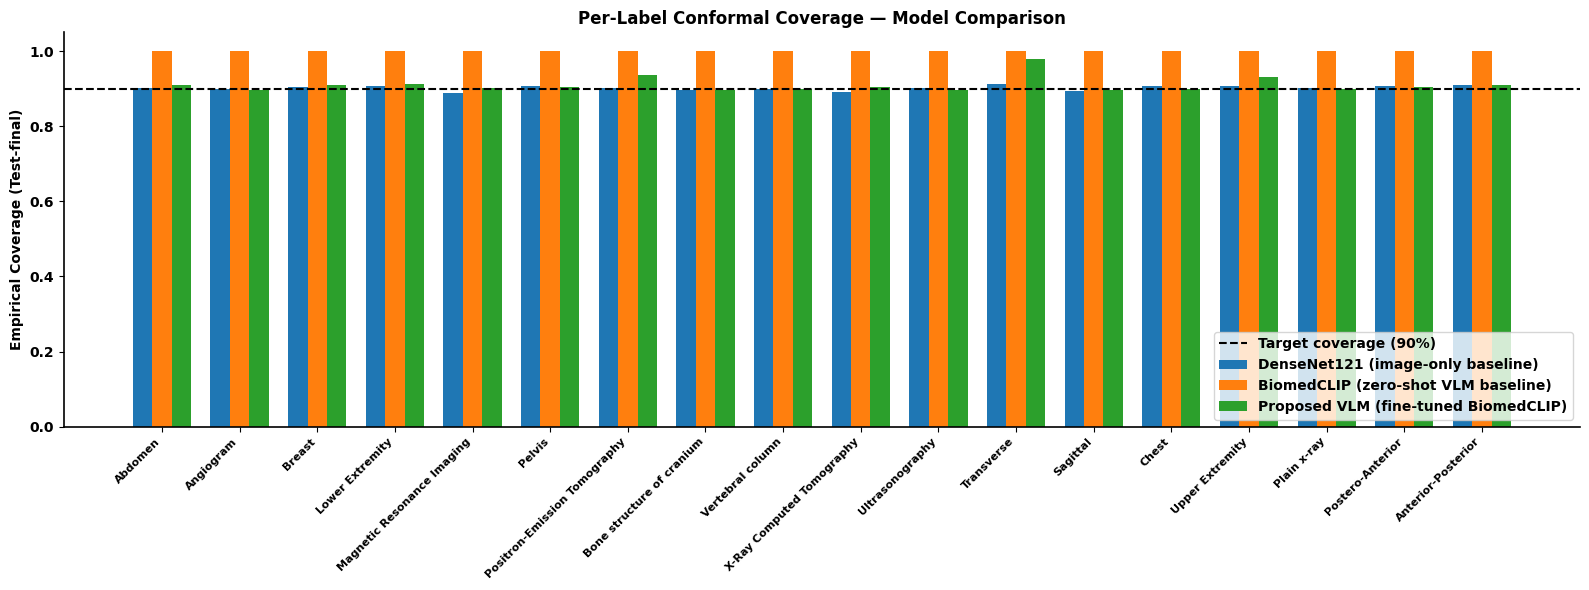

Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/figures/coverage_comparison.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/figures/coverage_comparison_300dpi.png


In [12]:
# ============================================================
# CELL 11 — COVERAGE COMPARISON FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.linewidth": 1.2,
})

model_names = [m["display_name"] for m in MODEL_REGISTRY]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(N_LABELS)
width = 0.25

for i, name in enumerate(model_names):
    subset = conformal_per_label_df.loc[conformal_per_label_df["Model"] == name].set_index("Label_Name")
    values = [subset.loc[label, "Empirical_Coverage"] for label in LABEL_NAMES]
    ax.bar(x + (i - 1) * width, values, width, label=name, color=colors[i])

ax.axhline(TARGET_COVERAGE, color="black", linestyle="--", linewidth=1.5,
           label=f"Target coverage ({TARGET_COVERAGE:.0%})")
ax.set_xticks(x)
ax.set_xticklabels(LABEL_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Empirical Coverage (Test-final)")
ax.set_title("Per-Label Conformal Coverage — Model Comparison", fontweight="bold")
ax.legend(frameon=True, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(COVERAGE_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(COVERAGE_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", COVERAGE_FIGURE_PDF)
print("Saved:", COVERAGE_FIGURE_PNG)


## 11. Publication-quality figure — prediction-set-size efficiency comparison

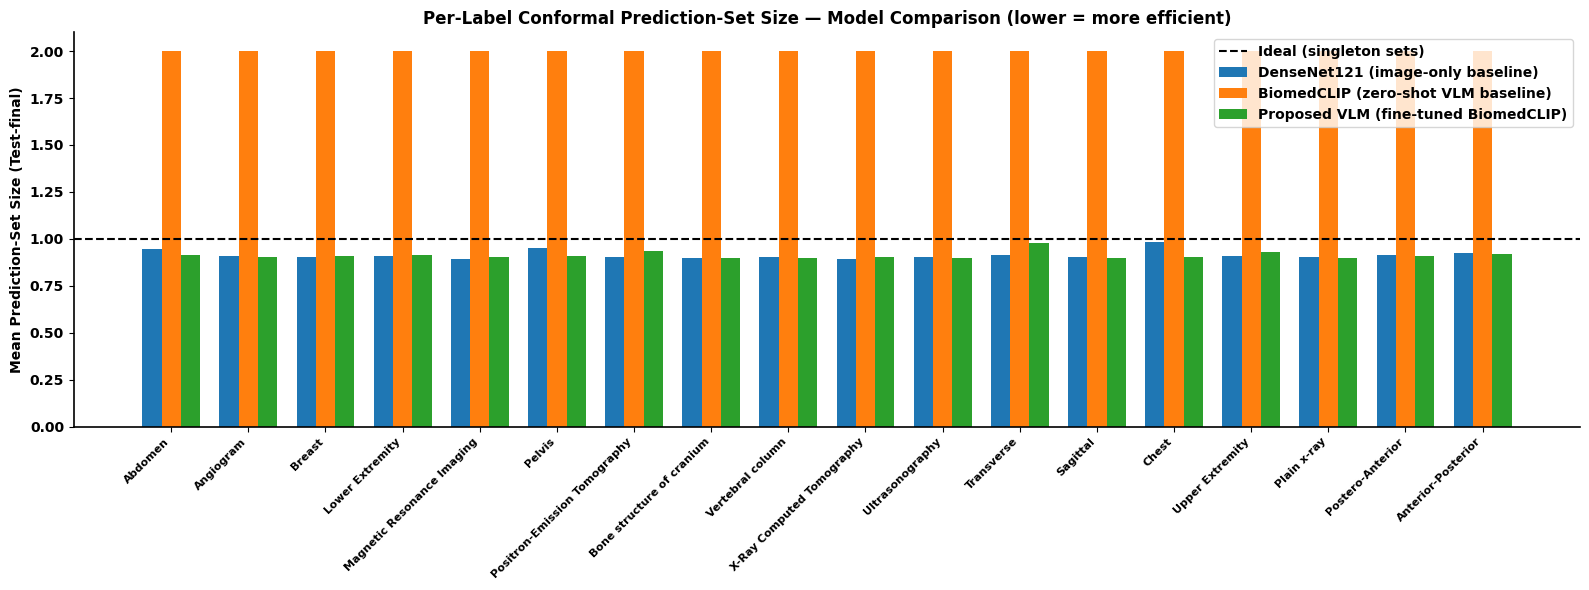

Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/figures/prediction_set_size_comparison.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/figures/prediction_set_size_comparison_300dpi.png


In [13]:
# ============================================================
# CELL 12 — PREDICTION SET SIZE (EFFICIENCY) COMPARISON FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))

for i, name in enumerate(model_names):
    subset = conformal_per_label_df.loc[conformal_per_label_df["Model"] == name].set_index("Label_Name")
    values = [subset.loc[label, "Mean_Set_Size"] for label in LABEL_NAMES]
    ax.bar(x + (i - 1) * width, values, width, label=name, color=colors[i])

ax.axhline(1.0, color="black", linestyle="--", linewidth=1.5, label="Ideal (singleton sets)")
ax.set_xticks(x)
ax.set_xticklabels(LABEL_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Mean Prediction-Set Size (Test-final)")
ax.set_title("Per-Label Conformal Prediction-Set Size — Model Comparison (lower = more efficient)",
              fontweight="bold")
ax.legend(frameon=True, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(SETSIZE_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(SETSIZE_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", SETSIZE_FIGURE_PDF)
print("Saved:", SETSIZE_FIGURE_PNG)


## 12. Save conformal configuration and reproducibility record

In [14]:
# ============================================================
# CELL 13 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

conformal_config = {
    "method": "Per-label independent split conformal prediction (LAC — Sadinle et al. 2019)",
    "alpha": ALPHA,
    "target_coverage": TARGET_COVERAGE,
    "calibration_source": "50/50 split of the original Test set (fixed seed)",
    "calibration_split_seed": SEED,
    "n_calibration": int(len(calibration_df)),
    "n_test_final": int(len(test_final_df)),
    "models_evaluated": [m["display_name"] for m in MODEL_REGISTRY],
    "per_label_qhat": {
        m["name"]: model_qhats[m["name"]] for m in MODEL_REGISTRY
    },
    "label_columns": LABEL_COLUMNS,
    "label_names": LABEL_NAMES,
}
safe_save_json(CONFORMAL_CONFIG_PATH, conformal_config)

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "08_ROCOv2_Conformal_Prediction",
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": package_version("sklearn"),
    "random_seed": SEED,
    "alpha": ALPHA,
    "models_evaluated": [m["name"] for m in MODEL_REGISTRY],
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/conformal_config.json
Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/reproducibility.json


## 13. Artifact manifest and final report

In [15]:
# ============================================================
# CELL 14 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    CALIBRATION_PREPARED_PATH, TEST_FINAL_PREPARED_PATH, CONFORMAL_CONFIG_PATH,
    TEST_FINAL_METRICS_PATH, CONFORMAL_PER_LABEL_PATH, CONFORMAL_SUMMARY_PATH,
    COVERAGE_FIGURE_PDF, COVERAGE_FIGURE_PNG, SETSIZE_FIGURE_PDF, SETSIZE_FIGURE_PNG,
    REPRODUCIBILITY_PATH,
]

manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"
safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

print("\n" + "=" * 60)
print("ROCOv2 CONFORMAL PREDICTION")
print("FINAL REPORT")
print("=" * 60)

print(f'''
Calibration source:
50/50 split of the original Test set (seed={SEED})

Calibration samples:
{len(calibration_df):,}
Test-final samples:
{len(test_final_df):,}

Conformal method:
Per-label independent split conformal (LAC)

Target coverage:
{TARGET_COVERAGE:.0%} (alpha={ALPHA})

------------------------------------------------------------
COVERAGE / EFFICIENCY SUMMARY (across all 18 labels)
------------------------------------------------------------
''')
display(conformal_summary_df)

print(f'''
------------------------------------------------------------
POINT-PREDICTION METRICS ON TEST-FINAL
------------------------------------------------------------
''')
display(test_final_metrics_df[["Model", "Micro_F1", "Macro_F1", "ROC_AUC_Macro", "Subset_Accuracy"]])

print(f'''
------------------------------------------------------------
DATA LEAKAGE
------------------------------------------------------------

Train/Calibration overlap:
PASS
Train/Test-final overlap:
PASS
Validation/Calibration overlap:
PASS
Validation/Test-final overlap:
PASS
Calibration/Test-final overlap:
PASS

Calibration used for:
Per-label conformal threshold (q-hat) fitting only

Test-final used for:
Final point-prediction metrics AND conformal coverage/efficiency evaluation only

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Independent Calibration split created:
YES

Conformal prediction implemented:
YES (per-label LAC, all three models)

Previous notebooks (01-07) modified:
NO

Dataset modified:
NO

Ready for Counterfactual Explanations / XAI notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

print("\nSTOP — Notebook 08 (Conformal Prediction) is complete.")
print("Not implemented here (by design): Counterfactual Explanations, XAI, Trust Score.")
print("Next notebook: 09_ROCOv2_Counterfactual_Explanations.ipynb")


,Artifact,Path,Exists,Size_KB
0,calibration_prepared.csv,/content/drive/MyDrive/ROCOv2/Prepared/calibra...,True,1332.48
1,test_final_prepared.csv,/content/drive/MyDrive/ROCOv2/Prepared/test_fi...,True,1338.53
2,conformal_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,3.12
3,test_final_point_metrics_all_models.csv,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,0.83
4,conformal_per_label_results.csv,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,7.10
5,conformal_summary_all_models.csv,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,0.35
6,coverage_comparison.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,20.84
7,coverage_comparison_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,398.00
8,prediction_set_size_comparison.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,19.53
9,prediction_set_size_comparison_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Conform...,True,407.32


Saved: /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/artifact_manifest.json

ROCOv2 CONFORMAL PREDICTION
FINAL REPORT

Calibration source:
50/50 split of the original Test set (seed=42)

Calibration samples:
4,935
Test-final samples:
4,935

Conformal method:
Per-label independent split conformal (LAC)

Target coverage:
90% (alpha=0.1)

------------------------------------------------------------
COVERAGE / EFFICIENCY SUMMARY (across all 18 labels)
------------------------------------------------------------



,Model,Mean_Coverage_Across_Labels,Min_Coverage_Across_Labels,Mean_Set_Size_Across_Labels,Labels_Notably_Below_Target_(>2pt)
0,DenseNet121 (image-only baseline),0.902173,0.887741,0.914590,0
1,BiomedCLIP (zero-shot VLM baseline),1.000000,1.000000,2.000000,0
2,Proposed VLM (fine-tuned BiomedCLIP),0.910571,0.896454,0.912406,0



------------------------------------------------------------
POINT-PREDICTION METRICS ON TEST-FINAL
------------------------------------------------------------



,Model,Micro_F1,Macro_F1,ROC_AUC_Macro,Subset_Accuracy
0,DenseNet121 (image-only baseline),0.857775,0.717013,0.969709,0.664640
1,BiomedCLIP (zero-shot VLM baseline),0.160983,0.147950,0.665886,0.000000
2,Proposed VLM (fine-tuned BiomedCLIP),0.928526,0.831051,0.995362,0.863425



------------------------------------------------------------
DATA LEAKAGE
------------------------------------------------------------

Train/Calibration overlap:
PASS
Train/Test-final overlap:
PASS
Validation/Calibration overlap:
PASS
Validation/Test-final overlap:
PASS
Calibration/Test-final overlap:
PASS

Calibration used for:
Per-label conformal threshold (q-hat) fitting only

Test-final used for:
Final point-prediction metrics AND conformal coverage/efficiency evaluation only

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Independent Calibration split created:
YES

Conformal prediction implemented:
YES (per-label LAC, all three models)

Previous notebooks (01-07) modified:
NO

Dataset modified:
NO

Ready for Counterfactual Explanations / XAI notebook:
YES


STOP — Notebook 08 (Conformal Prediction) is complete.
Not implemented here (by design): Counterfactual Explanations, XAI, Trust Scor